# Bicep gravity conversion and legacy model test
This notebook estimates gravity from the new watch recording, compares it with the old gravity signal, extracts the original four features, and runs the **unchanged saved scaler and Isolation Forest**.

Default example: old right-arm Typical recording 001 and Anisha's first right-arm set. New technique labels are unverified. Model outputs below are exploratory, not accuracy measurements.

Run all cells. Paths and movement windows are editable below. The existing local `ml/.venv` supports plots; scoring runs in the project's existing `session_pipeline/.venv`. No installation, retraining, upload, or source-recording changes are performed.

In [1]:
from pathlib import Path
import csv,json,sys,hashlib,subprocess
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation
from scipy.signal import butter,filtfilt,find_peaks
REPO=Path('/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo')
OLD_FILE=REPO/'Data/Raw/Typical/001_BicepCurl_R_T.csv'
NEW_FILE=Path('/Users/jadechng/Desktop/HomeStretch/recordings/1005/Anisha Bicep Curls_20261005-115528_1d1d07ea.csv')
FUSION_WINDOW=(0.,32.) # includes neutral hold, stops before reattachment
NEW_MOVEMENT_WINDOW=(7.,29.) # provisional visual selection, inspect below
OLD_MOVEMENT_WINDOW=(4.,32.) # provisional visual selection excluding opening and final rest
FS=50.
GRAVITY_SIGN=-1 # physical gravity = negative of stationary specific-force direction
MODEL=REPO/'mbientcode/isolation_forest.pkl'
SCALER=REPO/'mbientcode/scaler.pkl'
SCORING_PYTHON=REPO/'signal-processing/session_pipeline/.venv/bin/python'
FEATURES=['duration','norm_amp','dom_freq','log_tremor']
sys.path.insert(0,str(REPO/'signal-processing'))
from session_pipeline.reader import load_recording
from session_pipeline.orientation import estimate
with OLD_FILE.open(newline='') as f:old_rows=list(csv.DictReader(f))
ot=np.array([float(r['seconds_elapsed']) for r in old_rows]);ot-=ot[0]
og=np.array([[float(r['gravity'+axis]) for axis in 'XYZ'] for r in old_rows])
assert np.isfinite(og).all() and np.all(np.diff(ot)>0)
record=load_recording(NEW_FILE)
def crop(a,window):return a[(a[:,0]>=window[0])&(a[:,0]<=window[1])].copy()
blocks,info=estimate(crop(record['streams']['acceleration'],FUSION_WINDOW),crop(record['streams']['gyroscope'],FUSION_WINDOW),FS)
assert blocks,'No usable paired IMU data.'
print('Orientation diagnostic:',json.dumps(info,indent=2))
print('Source hashes:',{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [OLD_FILE,NEW_FILE,MODEL,SCALER]})

Orientation diagnostic: {
  "method": "six-axis-gravity-feedback-0.1",
  "status": "experimental_transfer",
  "convention": "body-to-world extrinsic xyz (Rz Ry Rx): roll X, pitch Y, relative yaw Z; output pitch,yaw,roll",
  "yaw_reference": "zero at each continuous block; unobservable absolute heading",
  "sampling_rate_hz": 50.0,
  "max_bridge_sec": 0.06,
  "gravity_feedback_gain_per_sec": 0.5,
  "calibration": "first_two_seconds_stationary",
  "gyro_bias_dps": [
    1.54875,
    -2.5025000000000004,
    -0.5687500000000001
  ],
  "blocks": 1,
  "notes": [
    "Sensor axes are not calibrated to the REHAB anatomical frame.",
    "Relative yaw can drift; it does not reproduce nine-axis heading.",
    "Dynamic acceleration can disturb tilt; correction gated to 0.85\u20131.15 g.",
    "Long gaps reset orientation; repetitions never cross them."
  ],
  "samples": 1601,
  "interpolated_samples": 411,
  "near_gimbal_samples": 0
}
Source hashes: {'001_BicepCurl_R_T.csv': '690d6433015cf9c22e2a

## Estimate gravity in the watch coordinate frame
The existing fusion routine estimates body-to-world orientation from acceleration and gyro data. Reconstruct that rotation from its declared extrinsic xyz Euler output, then rotate the world gravity vector into sensor coordinates. Gravity magnitude is 1 g by construction; that is a mathematical check, not proof of estimation accuracy.

The default negative sign represents physical gravity opposite stationary accelerometer specific force. The old logger's axis/sign convention and watch mounting are not independently verified. Global yaw does not affect the gravity vector, but tilt errors and dynamic acceleration do. Gaps over 60 ms reset fusion; no repetition will cross a reset. Short repaired gaps are reported. The second wearing period is excluded.

Old gravity median magnitude: 1.000000015239972


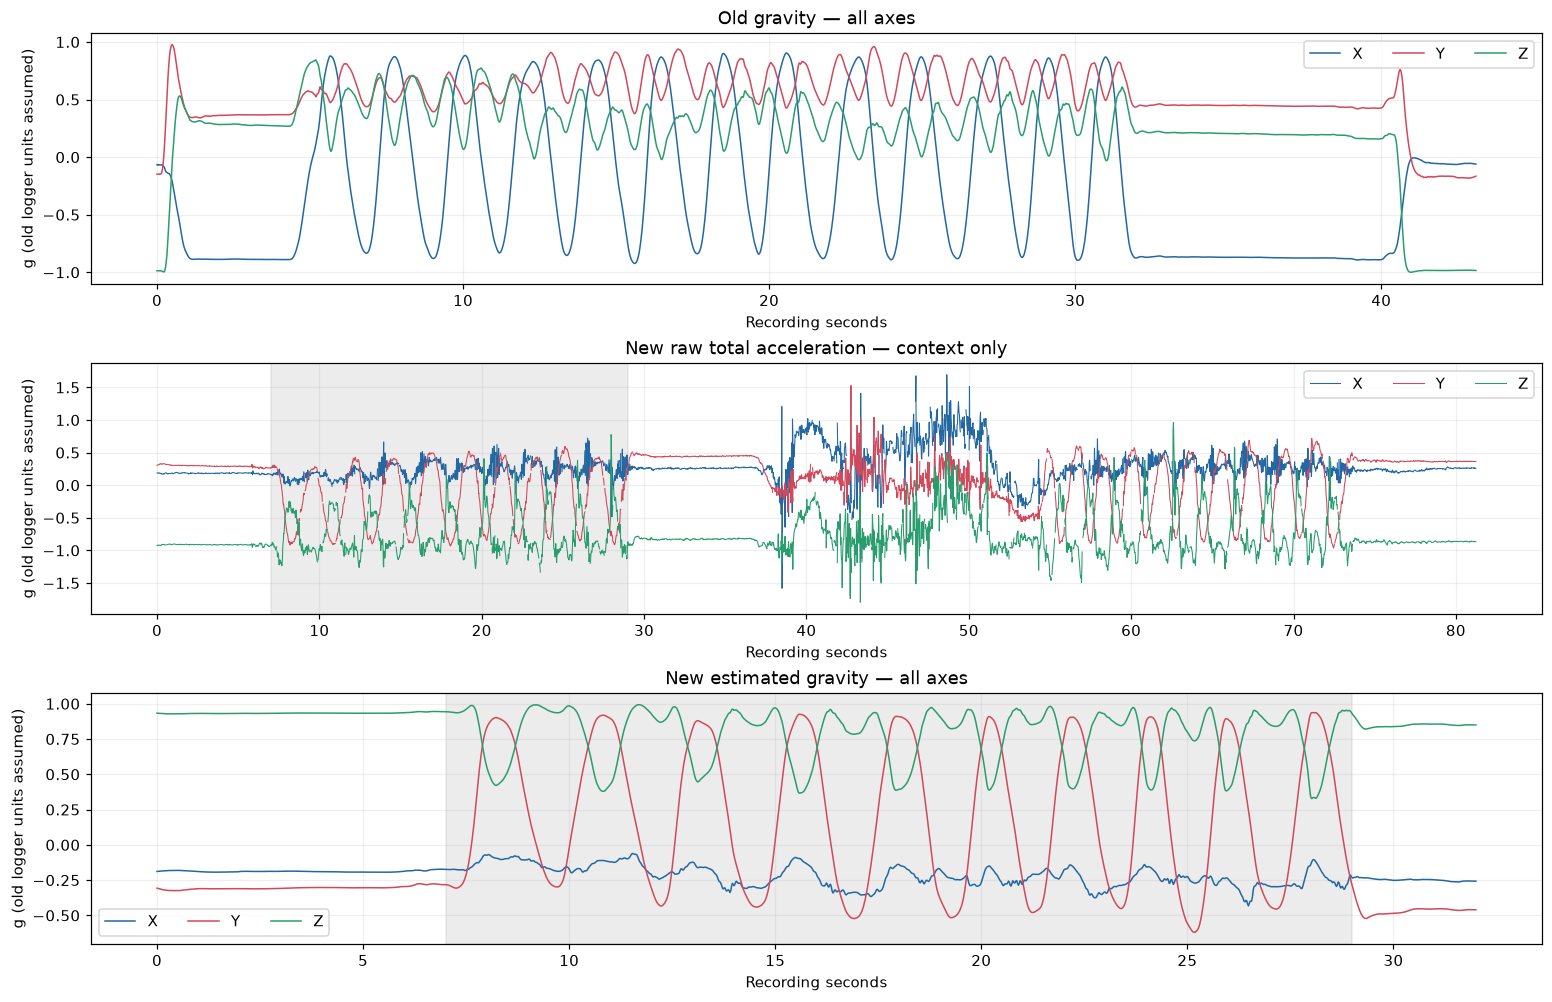

In [2]:
gravity_blocks=[]
for b in blocks:
    # estimator column order: pitch,yaw,roll -> scipy xyz: roll,pitch,yaw
    r=Rotation.from_euler('xyz',b['angles'][:,[2,0,1]],degrees=True)
    gravity=r.inv().apply([0.,0.,float(GRAVITY_SIGN)])
    assert np.allclose(np.linalg.norm(gravity,axis=1),1.,atol=1e-9)
    gravity_blocks.append(dict(time=b['time'],gravity=gravity,interpolated=b['interpolated']))
# Known-pose checks: identity gives downward z; 90-degree x tilt rotates gravity to -y.
assert np.allclose(Rotation.identity().inv().apply([0,0,-1]),[0,0,-1])
assert np.allclose(Rotation.from_euler('x',90,degrees=True).inv().apply([0,0,-1]),[0,-1,0],atol=1e-9)
fig,axes=plt.subplots(3,1,figsize=(14,9),constrained_layout=True)
colors=['#2368A2','#D1495B','#2A9D6F']
for k,c in enumerate(colors):
    axes[0].plot(ot,og[:,k],color=c,label='XYZ'[k],lw=1)
    a=record['streams']['acceleration'];v=a[:,k+1].copy();v[a[:,4]==0]=np.nan
    v[np.r_[False,np.diff(a[:,0])>.1]]=np.nan
    axes[1].plot(a[:,0],v,color=c,label='XYZ'[k],lw=.7)
    for j,b in enumerate(gravity_blocks):axes[2].plot(b['time'],b['gravity'][:,k],color=c,label='XYZ'[k] if j==0 else None,lw=1)
for ax,title in zip(axes,['Old gravity — all axes','New raw total acceleration — context only','New estimated gravity — all axes']):
    ax.set_title(title);ax.set_ylabel('g (old logger units assumed)');ax.set_xlabel('Recording seconds');ax.grid(alpha=.2);ax.legend(ncol=3)
for ax in axes[1:]:ax.axvspan(*NEW_MOVEMENT_WINDOW,color='gray',alpha=.15)
plt.show()
print('Old gravity median magnitude:',np.median(np.linalg.norm(og,axis=1)))

## Original segmentation and feature definitions
These functions are copied verbatim from the legacy `mbientimplenetation.ipynb` feature cell. Each analysis window is standardized by its own mean and standard deviation before segmentation, matching the legacy session normalization. Proposed peak-to-peak repetitions yield duration, relative amplitude, dominant frequency and log tremor ratio.

The legacy implementation used trimmed sessions. Here the new window is provisional and the old window is also provisional, so inspect and adjust the windows before treating the results as comparable. New continuous blocks are normalized separately when gaps split the selected window. Estimated gravity filtering may change the tremor feature compared with the old logger.

In [3]:
def highpass(x, Fs, cutoff_hz, order=2):
    nyq = 0.5 * Fs
    b, a = butter(order, cutoff_hz / nyq, btype='high')
    return filtfilt(b, a, x)

def lowpass(x, Fs, cutoff_hz, order=2):
    nyq = 0.5 * Fs
    b, a = butter(order, cutoff_hz / nyq, btype='low')
    return filtfilt(b, a, x)

def segment_reps(signal, time, Fs):
    sig = lowpass(signal, Fs, 1, order=2)
    sig = highpass(sig, Fs, 0.1, order=2)
    peaks, _ = find_peaks(sig, prominence=0.05, distance=Fs*1.0)
    rep_segments = []
    for i in range(len(peaks) - 1):
        t_start, t_end = time[peaks[i]], time[peaks[i+1]]
        mask = (time >= t_start) & (time <= t_end)
        rep_segments.append({
            'signal': signal[mask],
            'time':   time[mask],
            't_start': t_start,
            't_end':   t_end,
        })
    return rep_segments

def compute_snr_db(signal, Fs):
    movement = highpass(lowpass(signal, Fs, 2), Fs, 0.1)
    noise    = highpass(signal, Fs, 3)
    rms_s = np.sqrt(np.mean(movement**2))
    rms_n = np.sqrt(np.mean(noise**2))
    if rms_n == 0:
        return np.inf
    return 20 * np.log10(rms_s / rms_n)

def compute_tremor_energy_ratio(signal, Fs):
    signal = signal - np.mean(signal)
    freqs  = np.fft.rfftfreq(len(signal), d=1/Fs)
    power  = np.abs(np.fft.rfft(signal))**2
    move_p   = np.sum(power[(freqs >= 0.1) & (freqs <= 2)])
    tremor_p = np.sum(power[(freqs >= 3)   & (freqs <= 8)])
    if move_p == 0:
        return np.inf
    return tremor_p / move_p

def extract_rep_features(rep_signal, rep_time, Fs, all_peak_amps):
    sig = rep_signal
    t   = rep_time

    duration = t[-1] - t[0]

    peak_amp = np.max(sig) - np.min(sig)
    norm_amp = peak_amp / np.mean(all_peak_amps) if np.mean(all_peak_amps) > 0 else 0

    peak_idx  = np.argmax(sig)
    rise_time = t[peak_idx] - t[0]
    fall_time = t[-1] - t[peak_idx]
    # Cap symmetry instead of returning inf
    symmetry  = rise_time / fall_time if fall_time > 1e-6 else rise_time / 1e-6
    symmetry  = np.clip(symmetry, 0, 10)  # cap at 10 so outliers don't dominate

    zero_crossings = np.where(np.diff(np.sign(sig)))[0]
    zcr = len(zero_crossings) / duration if duration > 0 else 0

    freqs    = np.fft.rfftfreq(len(sig), d=1/Fs)
    power    = np.abs(np.fft.rfft(sig))**2
    dom_freq = freqs[np.argmax(power)] if len(power) > 0 else 0

    snr_db       = compute_snr_db(sig, Fs)
    tremor_ratio = compute_tremor_energy_ratio(sig, Fs)
    log_tremor   = np.log10(tremor_ratio + 1)

    return {
        'duration':   duration,
        'norm_amp':   norm_amp,
        'symmetry':   symmetry,
        'zcr':        zcr,
        'dom_freq':   dom_freq,
        'snr_db':     snr_db,
        'log_tremor': log_tremor,
    }

Feature rows: 41
New axes can produce different candidate boundaries; these are not matched repetitions.


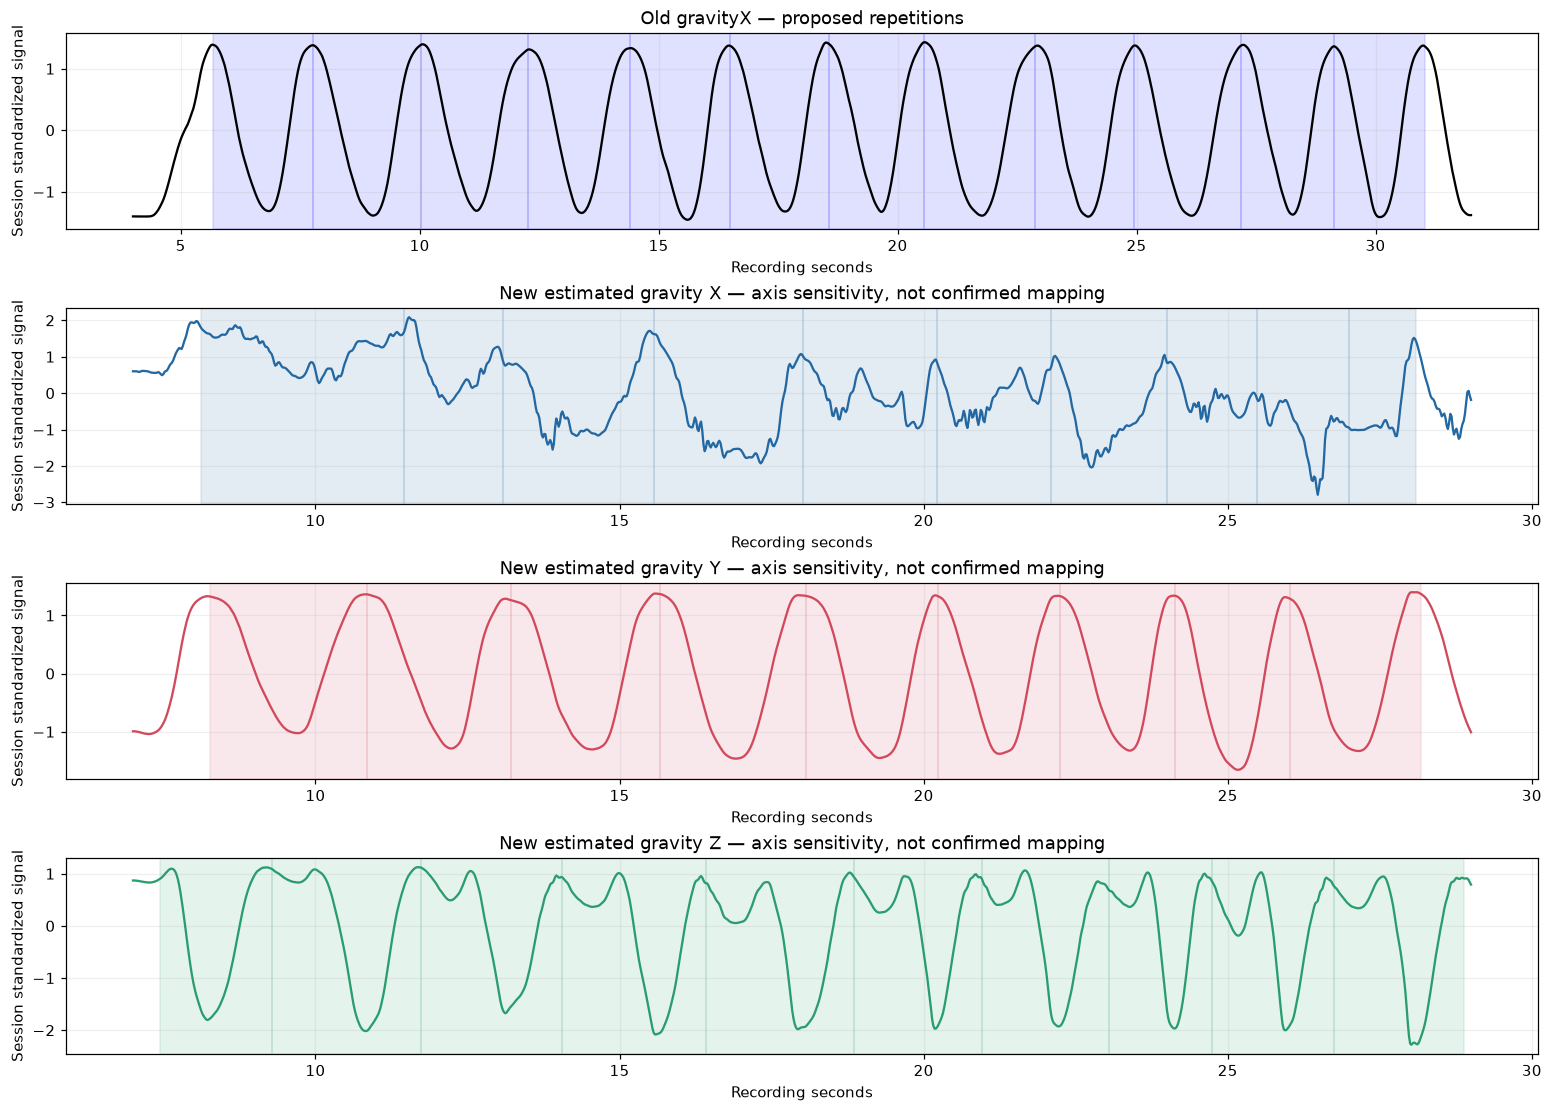

In [4]:
def analyze(t,signal):
    assert len(t)==len(signal) and np.all(np.diff(t)>0)
    rate=1/np.mean(np.diff(t))
    if len(t)<50 or rate<=16 or np.std(signal)<1e-8:return [],[],None
    normalized=(signal-np.mean(signal))/(np.std(signal)+1e-8)
    reps=segment_reps(normalized,t,rate)
    amps=[np.ptp(r['signal']) for r in reps]
    result=[]
    for i,rep in enumerate(reps):
        if len(rep['signal'])<max(16,int(.3*rate)):continue
        f=extract_rep_features(rep['signal'],rep['time'],rate,amps)
        if not np.isfinite([f[k] for k in FEATURES]).all():continue
        result.append(dict(rep=i,start=rep['t_start'],end=rep['t_end'],**{k:f[k] for k in FEATURES}))
    return result,reps,normalized
old_keep=np.ones(len(ot),bool) if OLD_MOVEMENT_WINDOW is None else (ot>=OLD_MOVEMENT_WINDOW[0])&(ot<=OLD_MOVEMENT_WINDOW[1])
old_features,old_reps,old_normalized=analyze(ot[old_keep],og[old_keep,0])
rows=[dict(source='old gravityX',axis='X',block=0,interpolated_fraction=0.,**r) for r in old_features]
fig,axes=plt.subplots(4,1,figsize=(14,10),constrained_layout=True)
axes[0].plot(ot[old_keep],old_normalized,color='black')
for r in old_features:axes[0].axvspan(r['start'],r['end'],alpha=.12,color='blue')
axes[0].set_title('Old gravityX — proposed repetitions')
for axis in range(3):
    for block_id,b in enumerate(gravity_blocks):
        keep=(b['time']>=NEW_MOVEMENT_WINDOW[0])&(b['time']<=NEW_MOVEMENT_WINDOW[1])
        if keep.sum()<50:continue
        t=b['time'][keep];g=b['gravity'][keep,axis]
        features,reps,norm=analyze(t,g)
        if norm is None:continue
        axes[axis+1].plot(t,norm,color=colors[axis])
        for f in features:
            in_rep=(b['time']>=f['start'])&(b['time']<=f['end'])
            repaired=float(b['interpolated'][in_rep].mean())
            rows.append(dict(source='new estimated gravity',axis='XYZ'[axis],block=block_id,interpolated_fraction=repaired,**f))
            axes[axis+1].axvspan(f['start'],f['end'],alpha=.12,color=colors[axis])
    axes[axis+1].set_title('New estimated gravity '+'XYZ'[axis]+' — axis sensitivity, not confirmed mapping')
for ax in axes:ax.set_xlabel('Recording seconds');ax.set_ylabel('Session standardized signal');ax.grid(alpha=.2)
plt.show()
print('Feature rows:',len(rows))
print('New axes can produce different candidate boundaries; these are not matched repetitions.')

## Test the unchanged model and scaler
Load only the trusted project artifacts named above. Scoring occurs in the existing compatible environment, and version warnings stop execution. No fit method is called.

All three watch-axis hypotheses are shown. **Do not choose an axis by its Typical rate.** That would select the result you want rather than establish alignment. Predictions describe the saved model's response, not verified technique. The original forest boundary is decision_function = 0; the later Mbient adapter used −0.19. Both thresholds are shown explicitly, without retuning.

In [5]:
worker = r"""
import sys,json,warnings,joblib,pandas as pd
from sklearn.exceptions import InconsistentVersionWarning
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
warnings.simplefilter('error',InconsistentVersionWarning)
x=json.load(sys.stdin);model=joblib.load(x['model']);scaler=joblib.load(x['scaler'])
assert isinstance(model,IsolationForest) and isinstance(scaler,StandardScaler)
assert model.n_features_in_==4 and list(scaler.feature_names_in_)==x['features']
f=pd.DataFrame(x['rows'],columns=x['features'])
print(json.dumps({'scores':model.decision_function(scaler.transform(f)).tolist()}))
"""
assert rows,'No feature rows to score.'
request=dict(model=str(MODEL),scaler=str(SCALER),features=FEATURES,rows=[[r[k] for k in FEATURES] for r in rows])
run=subprocess.run([str(SCORING_PYTHON),'-c',worker],input=json.dumps(request),text=True,capture_output=True,timeout=60)
if run.returncode:raise RuntimeError(run.stderr)
scores=json.loads(run.stdout)['scores']
for row,score in zip(rows,scores,strict=True):
    row.update(decision_score=score,model_boundary_label='Typical' if score>=0 else 'Atypical',
               adapter_threshold_label='Typical' if score>-.19 else 'Atypical')
print('Source / axis | candidate reps | Typical at 0 | Typical at -0.19')
for key in sorted(set((r['source'],r['axis']) for r in rows)):
    selected=[r for r in rows if (r['source'],r['axis'])==key]
    print(key,len(selected),sum(r['model_boundary_label']=='Typical' for r in selected),sum(r['adapter_threshold_label']=='Typical' for r in selected))
print('Diagnostic only: no verified new labels, no accuracy estimate, no axis chosen.')
# Run this cell again after changing the windows to refresh the table.
OUTPUT_DIR=Path.cwd()/'bicep_gravity_outputs';OUTPUT_DIR.mkdir(exist_ok=True)
with (OUTPUT_DIR/'features_and_experimental_scores.csv').open('w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
print('Saved:',OUTPUT_DIR/'features_and_experimental_scores.csv')

Source / axis | candidate reps | Typical at 0 | Typical at -0.19
('new estimated gravity', 'X') 10 0 0
('new estimated gravity', 'Y') 9 8 9
('new estimated gravity', 'Z') 10 1 10
('old gravityX', 'X') 12 12 12
Diagnostic only: no verified new labels, no accuracy estimate, no axis chosen.
Saved: /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_gravity_outputs/features_and_experimental_scores.csv


## What this establishes
The new raw data can be converted into an estimated gravity signal and passed through the old feature definitions, scaler and forest. This demonstrates a runnable transfer experiment. It does not validate mounting alignment or prediction accuracy.

Before interpreting the scores: review the shaded repetitions, confirm the correct gravity projection from device placement, and check performance on independently reviewed watch repetitions. Do not refit the scaler alone while keeping the forest fixed. Keep both model artifacts unchanged for this test; retraining is a separate experiment.